In [1]:
# ── Fix working directory so paths work from any location ────────────────────
import os, sys

# Always resolve paths relative to the project root (one level above notebooks/)
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)
print(f'✅ Working directory set to: {os.getcwd()}')


✅ Working directory set to: c:\Users\khali\Downloads\emotion_project\emotion_final


## 1 Présentation du Dataset GoEmotions

**GoEmotions** est un dataset créé par Google Research, composé de ~54,000 commentaires Reddit annotés manuellement avec **28 émotions** distinctes.

Le fichier `emotions.txt` fourni liste les 28 noms d'émotions (une par ligne), et leur position (index 0 à 27) correspond au label numérique :

| Index | Émotion | Index | Émotion |
|---|---|---|---|
| 0 | admiration | 14 | fear |
| 1 | amusement | 15 | gratitude |
| 2 | anger | 16 | grief |
| 3 | annoyance | 17 | joy |
| ... | ... | ... | ... |
| 27 | neutral | | |

| Caractéristique | Valeur |
|---|---|
| Nombre de textes | ~54,000 |
| Nombre de classes | 28 émotions |
| Langue | Anglais |
| Source | Reddit |
| Problème | Déséquilibre important entre classes |

## 2. Chargement des Données

In [2]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Imports de toutes les bibliothèques
# ═══════════════════════════════════════════════════════════════


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import time
from datasets import load_dataset



# Configuration globale des graphiques :
# dpi=120 → haute résolution (120 points par pouce)
# font.family → police utilisée dans tous les graphiques
plt.rcParams['figure.dpi']   = 120
plt.rcParams['font.family']  = 'DejaVu Sans'

print('✅ Imports généraux OK')

c:\Users\khali\anaconda3\envs\emotion\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Imports généraux OK


In [3]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Chargement du dataset depuis HuggingFace
# ═══════════════════════════════════════════════════════════════
#
# load_dataset() : fonction de la bibliothèque 'datasets' (HuggingFace)


print('⏳ Chargement du dataset GoEmotions...')
dataset = load_dataset('google-research-datasets/go_emotions', 'simplified')

print('\n📦 Structure du dataset :')
print(dataset)

⏳ Chargement du dataset GoEmotions...



📦 Structure du dataset :
DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


In [4]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Lecture du fichier emotions.txt (fourni dans l'énoncé)
# ═══════════════════════════════════════════════════════════════


import os
import urllib.request

EMOTIONS_FILE = 'emotions.txt'
# utilise emotion.txt si est déjà téléchargé sinon le télécharge depuis GitHub
if not os.path.exists(EMOTIONS_FILE):
    url = ('https://raw.githubusercontent.com/google-research/'
           'google-research/master/goemotions/data/emotions.txt')
    urllib.request.urlretrieve(url, EMOTIONS_FILE)
    print('📥 emotions.txt téléchargé depuis GitHub')
else:
    print('✅ emotions.txt trouvé localement')

emotion_mapping = {}
with open(EMOTIONS_FILE, 'r') as f:
    # On utilise enumerate(f) qui génère automatiquement le numéro de ligne (idx) sans qu'il soit écrit dans le fichier.
    for idx, line in enumerate(f):
        name = line.strip()
        # if name :ignore les lignes vides (sécurité)
        if name:
            emotion_mapping[idx] = name

print(f'\n📋 {len(emotion_mapping)} émotions chargées depuis emotions.txt :')
for k, v in emotion_mapping.items():
    print(f'   {k:2d} → {v}')

📥 emotions.txt téléchargé depuis GitHub

📋 28 émotions chargées depuis emotions.txt :
    0 → admiration
    1 → amusement
    2 → anger
    3 → annoyance
    4 → approval
    5 → caring
    6 → confusion
    7 → curiosity
    8 → desire
    9 → disappointment
   10 → disapproval
   11 → disgust
   12 → embarrassment
   13 → excitement
   14 → fear
   15 → gratitude
   16 → grief
   17 → joy
   18 → love
   19 → nervousness
   20 → optimism
   21 → pride
   22 → realization
   23 → relief
   24 → remorse
   25 → sadness
   26 → surprise
   27 → neutral


In [5]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Conversion en DataFrames + création des copies de travail
# ═══════════════════════════════════════════════════════════════

# ── Données originales (jamais modifiées) ─────────────────────
# convertit les splits HuggingFace en DataFrames pandas (colonnes : text, labels, id)
df_train_raw = dataset['train'].to_pandas()
df_val_raw   = dataset['validation'].to_pandas()
df_test_raw  = dataset['test'].to_pandas()

# ── Copies de travail ─────────────────────────────────────────
df_train = df_train_raw.copy()
df_val   = df_val_raw.copy()
df_test  = df_test_raw.copy()

# ── Extraction du label + mapping vers le nom de l'émotion ────
# on prend label = x[0] (premier élément de la liste) ou 27 (neutral) si la liste est vide, puis on mappe vers le nom de l'émotion
#car label contient une LISTE d'entiers (ex: [2], [17, 3])
for df in [df_train, df_val, df_test]:
    df['label']   = df['labels'].apply(lambda x: x[0] if len(x) > 0 else 27)
    df['emotion'] = df['label'].map(emotion_mapping)

# ── Dataset complet (pour EDA uniquement) ─────────────────────
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

print('📊 Tailles des splits :')
print(f'  Train      : {len(df_train):,} exemples')
print(f'  Validation : {len(df_val):,} exemples')
print(f'  Test       : {len(df_test):,} exemples')
print(f'  Total      : {len(df_all):,} exemples')
print(f'\n✅ Originaux préservés dans df_train_raw / df_val_raw / df_test_raw')
print(f'✅ Travail effectué sur les copies df_train / df_val / df_test')

print('\n🔍 Aperçu (5 premières lignes) :')
df_train[['text', 'label', 'emotion']].head(10)

📊 Tailles des splits :
  Train      : 43,410 exemples
  Validation : 5,426 exemples
  Test       : 5,427 exemples
  Total      : 54,263 exemples

✅ Originaux préservés dans df_train_raw / df_val_raw / df_test_raw
✅ Travail effectué sur les copies df_train / df_val / df_test

🔍 Aperçu (5 premières lignes) :


,text,label,emotion
0,My favourite food is anything I didn't have to...,27,neutral
1,"Now if he does off himself, everyone will thin...",27,neutral
2,WHY THE FUCK IS BAYLESS ISOING,2,anger
3,To make her feel threatened,14,fear
4,Dirty Southern Wankers,3,annoyance
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,26,surprise
6,Yes I heard abt the f bombs! That has to be wh...,15,gratitude
7,We need more boards and to create a bit more s...,8,desire
8,Damn youtube and outrage drama is super lucrat...,0,admiration
9,It might be linked to the trust factor of your...,27,neutral


## 3. Analyse Exploratoire des Données (EDA)

In [6]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Vérification de la structure du DataFrame et des valeurs nulles
# ═══════════════════════════════════════════════════════════════
df_all.info()
print("\nValeurs nulles:", df_all.isnull().sum().to_dict())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54263 entries, 0 to 54262
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text     54263 non-null  object
 1   labels   54263 non-null  object
 2   id       54263 non-null  object
 3   label    54263 non-null  int64 
 4   emotion  54263 non-null  object
dtypes: int64(1), object(4)
memory usage: 2.1+ MB

Valeurs nulles: {'text': 0, 'labels': 0, 'id': 0, 'label': 0, 'emotion': 0}


In [7]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Statistiques descriptives générales
# ═══════════════════════════════════════════════════════════════

df_train['text_length'] = df_train['text'].apply(len)
df_train['word_count']  = df_train['text'].apply(lambda x: len(x.split()))

print('=' * 55)
print('       STATISTIQUES GÉNÉRALES DU DATASET')
print('=' * 55)
print(f'\n📝 Longueur des textes (caractères) :')
print(df_train['text_length'].describe().round(1).to_string())
print(f'\n📝 Nombre de mots par texte :')
print(df_train['word_count'].describe().round(1).to_string())
print(f'\n📝 Nombre de classes distinctes : {df_train["emotion"].nunique()}')
print(f'   Classes : {sorted(df_train["emotion"].unique())}')

       STATISTIQUES GÉNÉRALES DU DATASET

📝 Longueur des textes (caractères) :
count    43410.0
mean        68.4
std         36.7
min          2.0
25%         38.0
50%         65.0
75%         96.0
max        703.0

📝 Nombre de mots par texte :
count    43410.0
mean        12.8
std          6.7
min          1.0
25%          7.0
50%         12.0
75%         18.0
max         33.0

📝 Nombre de classes distinctes : 28
   Classes : ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'neutral', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise']


In [8]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Distribution des 28 émotions — TOUTES les classes
# ═══════════════════════════════════════════════════════════════

emotion_counts = df_train['emotion'].value_counts()
emotion_pcts   = df_train['emotion'].value_counts(normalize=True) * 100

print('📊 Distribution COMPLÈTE des 28 émotions (train) :')
print(f'{"Émotion":<18} {"Count":>7}  {"Pct":>6}')
print('-' * 35)
for emo in emotion_counts.index:
    bar = '█' * int(emotion_pcts[emo] / 0.4)
    print(f'{emo:<18} {emotion_counts[emo]:>7,}  {emotion_pcts[emo]:>5.1f}%  {bar}')

print(f'\n⚠️  Classe la plus fréquente : {emotion_counts.index[0]} '
      f'({emotion_counts.iloc[0]:,} = {emotion_pcts.iloc[0]:.1f}%)')
print(f'⚠️  Classe la plus rare      : {emotion_counts.index[-1]} '
      f'({emotion_counts.iloc[-1]:,} = {emotion_pcts.iloc[-1]:.1f}%)')
print(f'⚠️  Ratio max/min            : {emotion_counts.iloc[0]/emotion_counts.iloc[-1]:.0f}x')
print(f'\n→ Le dataset est FORTEMENT déséquilibré → nécessite un traitement !')

📊 Distribution COMPLÈTE des 28 émotions (train) :
Émotion              Count     Pct
-----------------------------------
neutral             12,823   29.5%  █████████████████████████████████████████████████████████████████████████
admiration           4,130    9.5%  ███████████████████████
approval             2,596    6.0%  ██████████████
amusement            2,244    5.2%  ████████████
annoyance            2,138    4.9%  ████████████
gratitude            2,096    4.8%  ████████████
curiosity            1,772    4.1%  ██████████
disapproval          1,651    3.8%  █████████
anger                1,547    3.6%  ████████
love                 1,533    3.5%  ████████
confusion            1,268    2.9%  ███████
disappointment       1,028    2.4%  █████
joy                  1,013    2.3%  █████
optimism               974    2.2%  █████
caring                 966    2.2%  █████
sadness                874    2.0%  █████
surprise               751    1.7%  ████
excitement             700    1.6

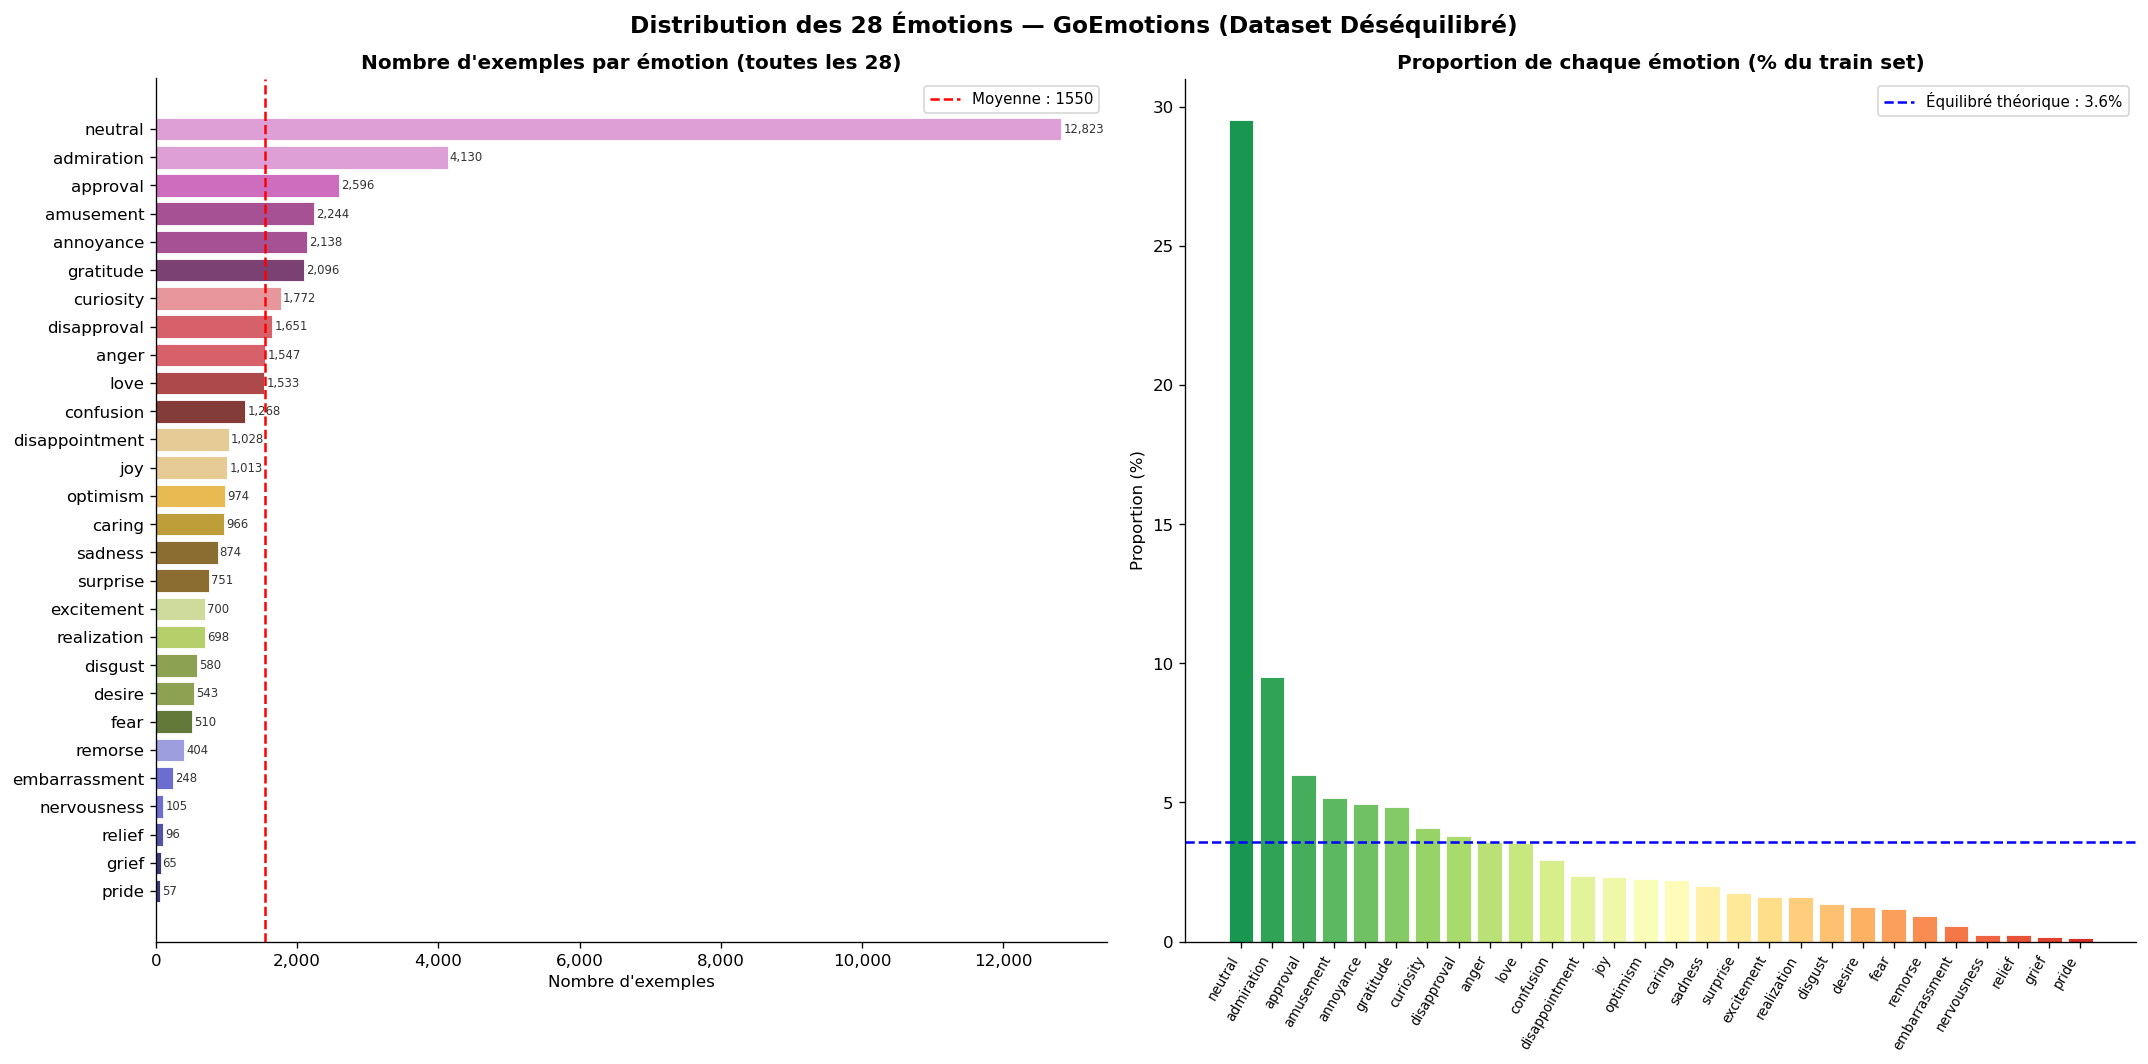

✅ Figure 1 sauvegardée (toutes les 28 émotions)


In [9]:
# ─── Graphiques de distribution : TOUTES les 28 émotions ─────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fig.suptitle('Distribution des 28 Émotions — GoEmotions (Dataset Déséquilibré)',
             fontsize=14, fontweight='bold')

# ── Panel gauche : toutes les émotions, barres horizontales ───────────────────
# barh() : bar chart horizontal, mieux pour lire les labels longs
# [::-1] : inverse la liste pour avoir la plus fréquente en HAUT
# np.linspace(0,1,28) : 28 couleurs uniformément réparties dans la palette
ax = axes[0]
colors_all = plt.cm.tab20b(np.linspace(0, 1, len(emotion_counts)))
bars = ax.barh(emotion_counts.index[::-1],
               emotion_counts.values[::-1],
               color=colors_all,
               edgecolor='white', linewidth=0.5)

# Ajouter la valeur numérique à droite de chaque barre
for bar, val in zip(bars, emotion_counts.values[::-1]):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=7, color='#333333')

# axvline : ligne verticale pointillée = moyenne si distribution équilibrée
mean_count = emotion_counts.mean()
ax.axvline(mean_count, color='red', linestyle='--', linewidth=1.5,
           label=f'Moyenne : {mean_count:.0f}')
ax.set_title('Nombre d\'exemples par émotion (toutes les 28)', fontweight='bold')
ax.set_xlabel('Nombre d\'exemples')
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.spines[['top', 'right']].set_visible(False)

# ── Panel droit : proportion en %, triée décroissante ─────────────────────────
# Montre le ratio entre la classe la plus fréquente et la plus rare
ax2 = axes[1]
colors_pct = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(emotion_pcts)))
ax2.bar(range(len(emotion_pcts)), emotion_pcts.values,
        color=colors_pct, edgecolor='white', linewidth=0.5)
ax2.set_xticks(range(len(emotion_pcts)))
ax2.set_xticklabels(emotion_pcts.index, rotation=60, ha='right', fontsize=8)

# Ligne rouge = proportion si toutes les classes étaient équilibrées
equil_pct = 100 / len(emotion_pcts)
ax2.axhline(equil_pct, color='blue', linestyle='--', linewidth=1.5,
            label=f'Équilibré théorique : {equil_pct:.1f}%')
ax2.set_title('Proportion de chaque émotion (% du train set)', fontweight='bold')
ax2.set_ylabel('Proportion (%)')
ax2.legend(fontsize=9)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig1_distribution_28_emotions.png', bbox_inches='tight')
plt.show()
print('✅ Figure 1 sauvegardée (toutes les 28 émotions)')

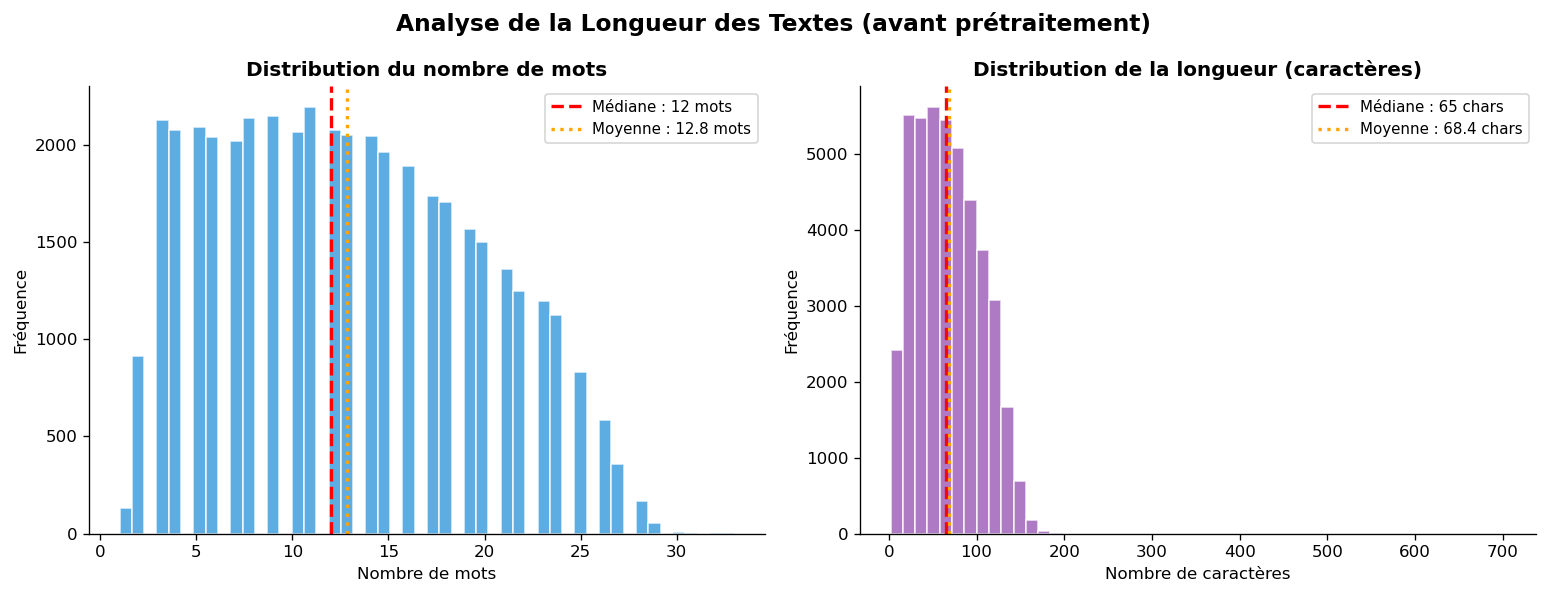

✅ Figure 2 sauvegardée


In [10]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Distribution de la longueur des textes
# ═══════════════════════════════════════════════════════════════


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Analyse de la Longueur des Textes (avant prétraitement)',
             fontsize=14, fontweight='bold')

for ax, col, color, xlabel, label in [
    (axes[0], 'word_count',  '#3498DB', 'Nombre de mots',       'mots'),
    (axes[1], 'text_length', '#9B59B6', 'Nombre de caractères', 'chars')
]:
    data = df_train[col]
    ax.hist(data, bins=50, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(data.median(), color='red',    linestyle='--', linewidth=2,
               label=f'Médiane : {data.median():.0f} {label}')
    ax.axvline(data.mean(),   color='orange', linestyle=':',  linewidth=2,
               label=f'Moyenne : {data.mean():.1f} {label}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Fréquence')
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_title('Distribution du nombre de mots', fontweight='bold')
axes[1].set_title('Distribution de la longueur (caractères)', fontweight='bold')

plt.tight_layout()
plt.savefig('fig2_longueur_textes.png', bbox_inches='tight')
plt.show()
print('✅ Figure 2 sauvegardée')

C:\Users\khali\AppData\Local\Temp\ipykernel_8552\1164138566.py:27: UserWarning: Glyph 127991 (\N{LABEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\khali\AppData\Local\Temp\ipykernel_8552\1164138566.py:28: UserWarning: Glyph 127991 (\N{LABEL}) missing from font(s) DejaVu Sans.
  plt.savefig('fig3_wordclouds.png', bbox_inches='tight')
c:\Users\khali\anaconda3\envs\emotion\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127991 (\N{LABEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


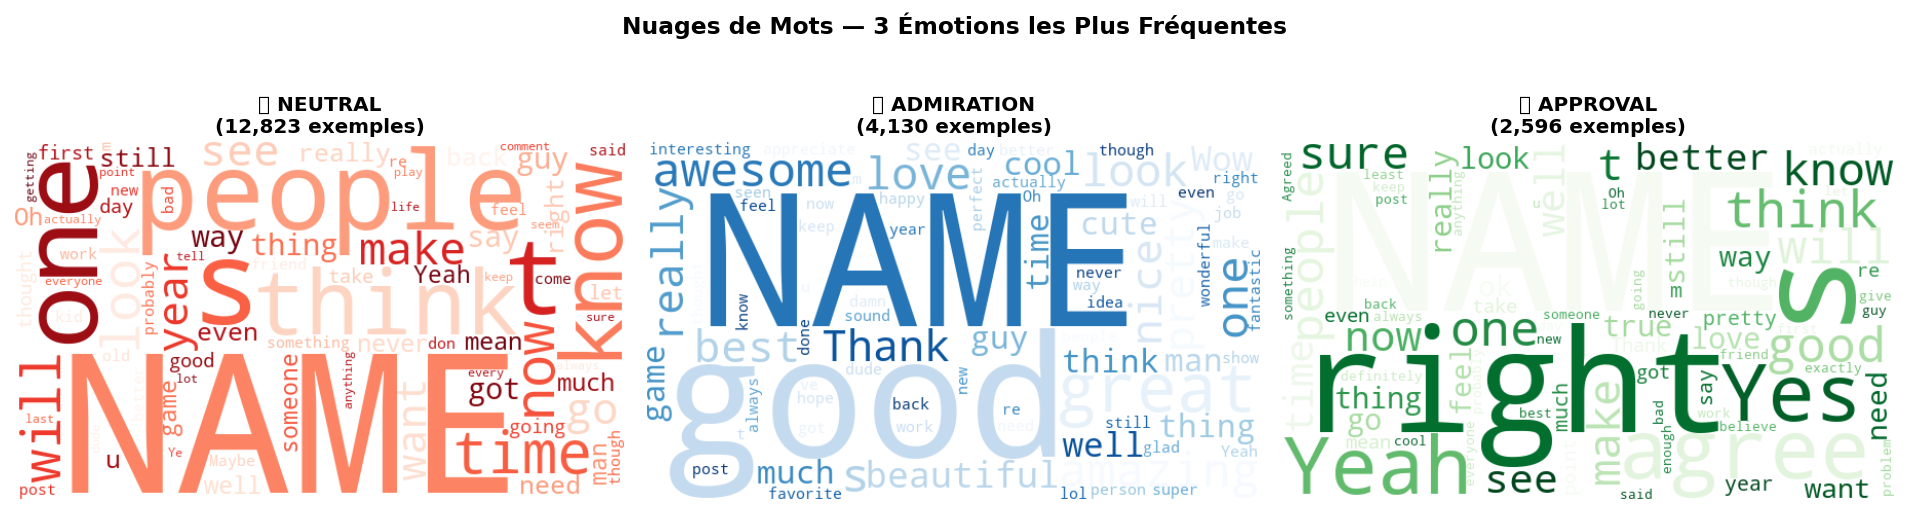

✅ Figure 3 sauvegardée


In [11]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : WordCloud pour les 3 émotions les plus fréquentes
# ═══════════════════════════════════════════════════════════════


try:
    from wordcloud import WordCloud

    top3 = emotion_counts.index[:3].tolist()
    cmaps = ['Reds', 'Blues', 'Greens']

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle('Nuages de Mots — 3 Émotions les Plus Fréquentes',
                 fontsize=14, fontweight='bold')

    for ax, emo, cmap in zip(axes, top3, cmaps):
        # Concaténer tous les textes de cette émotion
        corpus = ' '.join(df_train[df_train['emotion'] == emo]['text'].tolist())
        wc = WordCloud(width=600, height=350, background_color='white',
                       colormap=cmap, max_words=80,
                       collocations=False).generate(corpus)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f'🏷 {emo.upper()}\n({emotion_counts[emo]:,} exemples)',
                     fontweight='bold', fontsize=12)
        ax.axis('off')   # pas d'axes sur une image

    plt.tight_layout()
    plt.savefig('fig3_wordclouds.png', bbox_inches='tight')
    plt.show()
    print('✅ Figure 3 sauvegardée')
except ImportError:
    print('⚠️  pip install wordcloud')

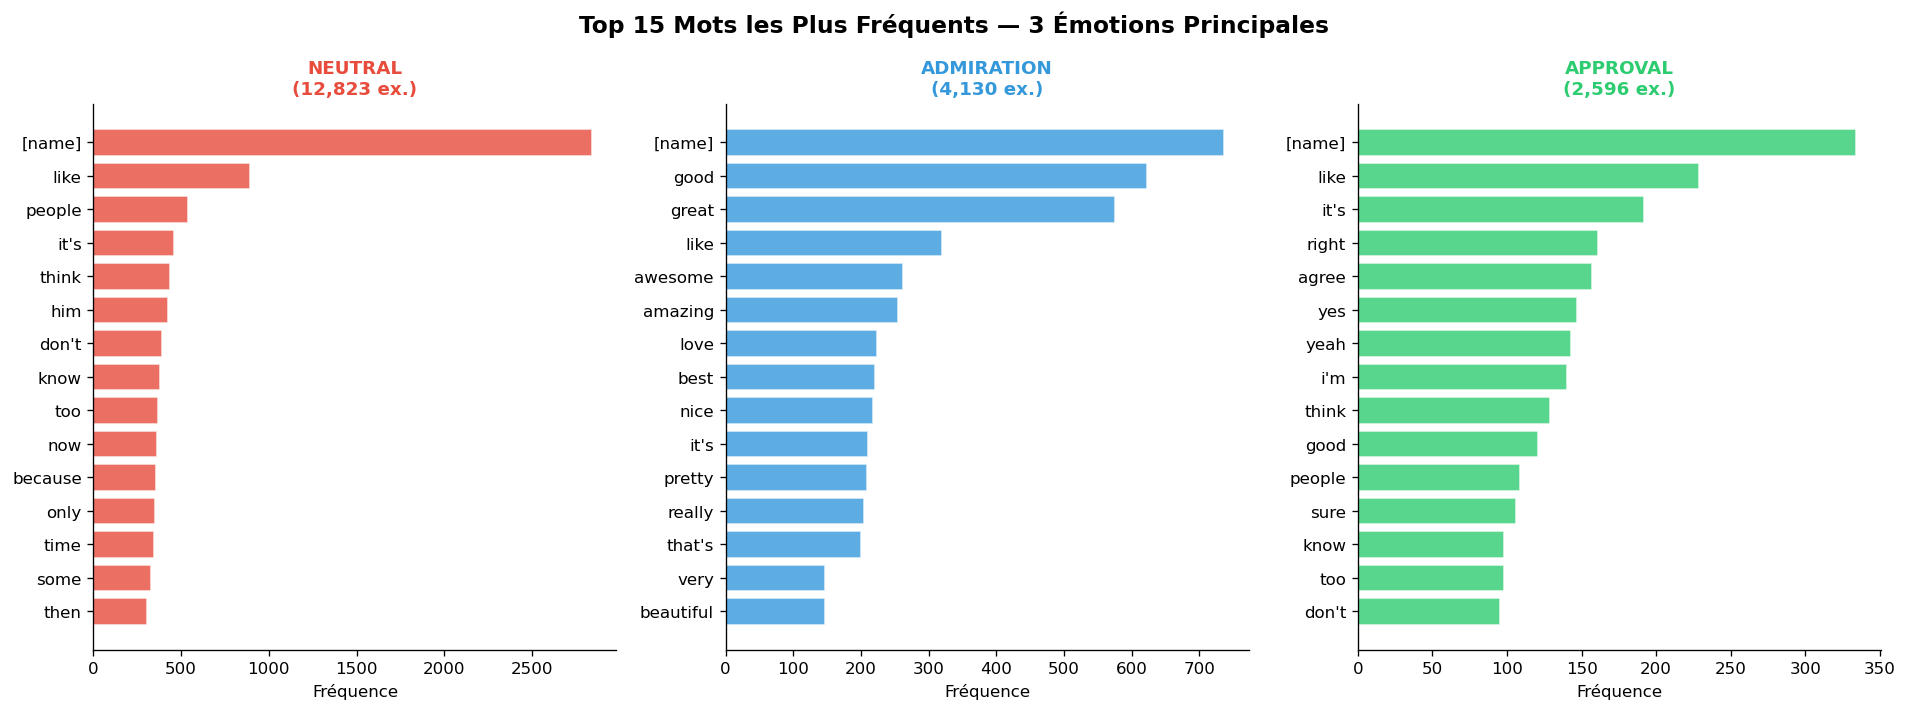

✅ Figure 4 sauvegardée


In [12]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Top 15 mots fréquents par émotion (3 émotions)
# ═══════════════════════════════════════════════════════════════
#
# On analyse les mots les plus représentatifs de chaque émotion
# AVANT le nettoyage pour voir ce que contient le texte brut.


from collections import Counter

basic_stops = {'the','a','an','and','or','but','in','on','at','to','for',
               'of','is','it','that','this','i','you','he','she','we','they',
               'was','are','be','been','have','has','had','do','does','did',
               'with','from','by','as','not','no','so','if','my','me','your',
               'its','his','her','our','their','what','how','when','where',
               'who','which','can','will','would','could','should','just',
               'all','more','about','up','out','them','one','there','get'}

top3 = emotion_counts.index[:3].tolist()
colors_top = ['#E74C3C', '#3498DB', '#2ECC71']

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Top 15 Mots les Plus Fréquents — 3 Émotions Principales',
             fontsize=14, fontweight='bold')

for ax, emo, color in zip(axes, top3, colors_top):
    words = []
    for text in df_train[df_train['emotion'] == emo]['text']:
        words.extend([
            w.lower().strip('.,!?"\';:-')
            for w in text.split()
            if w.lower().strip('.,!?"\';:-') not in basic_stops
            and len(w) > 2
        ])
    top_words = Counter(words).most_common(15)
    words_list, counts = zip(*top_words)

    ax.barh(range(15), counts, color=color, alpha=0.8, edgecolor='white')
    ax.set_yticks(range(15))
    ax.set_yticklabels(words_list, fontsize=10)
    ax.invert_yaxis()
    ax.set_title(f'{emo.upper()}\n({emotion_counts[emo]:,} ex.)',
                 fontweight='bold', color=color, fontsize=11)
    ax.set_xlabel('Fréquence')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig4_top_mots.png', bbox_inches='tight')
plt.show()
print('✅ Figure 4 sauvegardée')

In [13]:
import os, urllib.request

os.makedirs('data/raw',       exist_ok=True)
os.makedirs('data/processed', exist_ok=True)

# ✅ Convertir les labels numpy → listes Python AVANT de sauvegarder
for df in [df_train_raw, df_val_raw, df_test_raw]:
    df['labels'] = df['labels'].apply(lambda x: list(x) if hasattr(x, '__iter__') else x)

# Sauvegarde des splits bruts
df_train_raw.to_csv('data/raw/train.csv', index=False)
df_val_raw.to_csv(  'data/raw/val.csv',   index=False)
df_test_raw.to_csv( 'data/raw/test.csv',  index=False)
print('✅ Splits bruts sauvegardés dans data/raw/')

# Téléchargement de emotions.txt si absent
emotions_dest = 'data/raw/emotions.txt'
if not os.path.exists(emotions_dest):
    url = ('https://raw.githubusercontent.com/google-research/'
           'google-research/master/goemotions/data/emotions.txt')
    urllib.request.urlretrieve(url, emotions_dest)
    print('📥 emotions.txt téléchargé → data/raw/emotions.txt')
else:
    print('✅ emotions.txt déjà présent dans data/raw/')

✅ Splits bruts sauvegardés dans data/raw/
✅ emotions.txt déjà présent dans data/raw/


In [14]:
# ═══════════════════════════════════════════════════════════════
# CELLULE : Sauvegarde correcte depuis HuggingFace
# ═══════════════════════════════════════════════════════════════
import os, urllib.request
os.makedirs('data/raw', exist_ok=True)

# Vérification que le dataset est bien chargé
print(f"df_train_raw shape : {df_train_raw.shape}")
print(f"Colonnes           : {df_train_raw.columns.tolist()}")
print(f"Labels exemple     : {df_train_raw['labels'].iloc[0]}")
print(f"Type labels        : {type(df_train_raw['labels'].iloc[0])}")

# Convertir labels numpy → listes Python avec virgules
df_train_save = df_train_raw.copy()
df_val_save   = df_val_raw.copy()
df_test_save  = df_test_raw.copy()

for df in [df_train_save, df_val_save, df_test_save]:
    df['labels'] = df['labels'].apply(lambda x: [int(i) for i in x])

df_train_save.to_csv('data/raw/train.csv', index=False)
df_val_save.to_csv(  'data/raw/val.csv',   index=False)
df_test_save.to_csv( 'data/raw/test.csv',  index=False)
print('✅ train.csv / val.csv / test.csv sauvegardés')
print(f'   Tailles : {len(df_train_save):,} | {len(df_val_save):,} | {len(df_test_save):,}')

# Télécharger emotions.txt
emotions_dest = 'data/raw/emotions.txt'
if not os.path.exists(emotions_dest):
    url = ('https://raw.githubusercontent.com/google-research/'
           'google-research/master/goemotions/data/emotions.txt')
    urllib.request.urlretrieve(url, emotions_dest)
    print('✅ emotions.txt téléchargé')

df_train_raw shape : (43410, 3)
Colonnes           : ['text', 'labels', 'id']
Labels exemple     : [np.int64(27)]
Type labels        : <class 'list'>
✅ train.csv / val.csv / test.csv sauvegardés
   Tailles : 43,410 | 5,426 | 5,427
